# Assignment Module 2 — Part 1: a CNN trained from scratch

| Student ID | Name | Email |
|---|---|---|
| ... | ... | ... |
| ... | ... | ... |

We train a convolutional network from scratch on the 100 aircraft variants of FGVC-Aircraft, using only PyTorch
primitives (`nn.Conv2d`, `nn.BatchNorm2d`, `nn.Linear`, ...). Our goal is not only a good accuracy but a network in
which every component is justified by a measurement. We therefore build it as a **ladder**: we start from a plain
VGG-style network and change **one design choice at a time**, so that every difference in accuracy has a single
cause.

| part | what we train | question |
|---|---|---|
| **ladder** s0 | plain VGG: 3 stages x 1 block, no BatchNorm, flatten head, no augmentation | reference point |
| s1 | + BatchNorm after every convolution | does BN improve the network and its tolerance to the learning rate? |
| s2 | + global average pooling instead of flatten | is the large flatten head responsible for memorization? |
| s3 | + random resized crop and horizontal flip | how much does augmentation limit memorization? |
| s4 | + a 4th stage (512 channels) | does more capacity help once the network is regularized? |
| **depth x residual** | {plain, residual} x {11, 19, 31 convolutional layers}, three seeds each | do skip connections matter, and more so as depth grows? |
| **training recipe** | the three best networks + weight decay, label smoothing, dropout, random erasing, crop size and schedule, tuned by grid search, random search and confirmation with three seeds | which network is best once each one has its own tuned recipe? |

**Protocol.** All runs share the same budget: 224x224 images, 70 epochs, batch 64, SGD with momentum, 3 warmup
epochs followed by cosine decay. Each configuration is trained at three learning rates (0.1, 0.05, 0.01) and
represented by the best one, since different networks prefer different learning rates. Weight decay, label
smoothing, dropout and random erasing are disabled until the training recipe, so that the ladder and the depth x residual
experiment measure the architecture alone. **All choices are made on the validation split; test accuracy is only
reported.**

**Result.** The final model is a residual network with 19 convolutional layers (the stage layout of ResNet-18) trained
with the tuned recipe: **64.1% ± 0.7 validation and 64.0% ± 0.3 test accuracy** (mean ± std over three seeds).

## Setup

**How to run.** The notebook runs top to bottom on Colab (GPU runtime). All the runs reported below are stored in the
repository (`results/part1`) and are downloaded automatically: a run whose result already exists with the same
configuration is skipped, so the whole notebook, tables and plots included, reproduces our results in a few minutes
without training. Setting `RETRAIN = True` trains everything again (about 2.5 hours on an A100). The dataset is cached
once, already preprocessed, in Google Drive.

In [4]:
%pip install -q torchinfo

In [5]:
import contextlib, json, math, random, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchinfo
from torchvision import datasets
from torchvision.ops import roi_align
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")

# Mixed precision on CUDA only: bfloat16 where supported (A100, L4), float16 + loss scaling otherwise (T4)
AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (AMP and torch.cuda.is_bf16_supported()) else torch.float16

RETRAIN = False        # True: retrain runs even if their JSON already exists
SHOW_SUMMARY = True    # print the model summary when a run starts with a different architecture than the last one
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name()})" if AMP else "")
      + f" | amp: {AMP_DTYPE if AMP else 'off'} | torch {torch.__version__}")

device: cuda (Tesla T4) | amp: torch.bfloat16 | torch 2.11.0+cu130


### Paths

On Colab, results and the preprocessed image cache are kept in Google Drive, so that they survive the end of a
session; the stored results of the repository are downloaded there before anything else.

In [6]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path("/content/drive/MyDrive/ipcv/results/part1")
    CACHE_DIR = Path("/content/drive/MyDrive/ipcv/cache")
    DATA_ROOT = Path("/content/data")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
    RESULTS_DIR = REPO_DIR / "results" / "part1"
    DATA_ROOT = Path.home() / "data" / "fgvc"
    CACHE_DIR = DATA_ROOT / "cache"

for d in (RESULTS_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("results ->", RESULTS_DIR)

GITHUB_REPO, GITHUB_REF = "jortikcode/100planes-X-IPCV", "main"   # a branch, or a tag to freeze the results
FETCH_RESULTS = IN_COLAB      # locally the repo already contains them


def fetch_results(repo, ref, dest):
    # Download the repo as one archive and copy its results/part1 JSON files into dest, never overwriting.
    import io, tarfile, urllib.request
    with urllib.request.urlopen(f"https://github.com/{repo}/archive/{ref}.tar.gz") as response:
        archive = tarfile.open(fileobj=io.BytesIO(response.read()), mode="r:gz")
    added = kept = 0
    for member in archive.getmembers():
        path = member.name.split("/", 1)[-1]                 # drop the "<repo>-<ref>/" prefix
        name = path.rsplit("/", 1)[-1]
        if (not (member.isfile() and path.startswith("results/part1/") and name.endswith(".json"))
                or ".." in path or name.startswith(".")):
            continue
        target = dest / path[len("results/part1/"):]
        if target.exists():
            kept += 1
            continue
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.extractfile(member).read())
        added += 1
    print(f"results from github.com/{repo} ({ref}): {added} downloaded, {kept} already present")


if FETCH_RESULTS:
    fetch_results(GITHUB_REPO, GITHUB_REF, RESULTS_DIR)

Mounted at /content/drive
results -> /content/drive/MyDrive/ipcv/results/part1
results from github.com/jortikcode/100planes-X-IPCV (main): 0 downloaded, 0 already present


### Reproducibility

We seed every source of randomness (initialization, data order, augmentation) and keep cuDNN deterministic, so that a
configuration trained twice with the same seed gives the same result. Training a configuration with different seeds
is how we measure run-to-run noise.

In [7]:
def fix_random(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


fix_random(42)

## Configuration

`BASE` holds every fixed choice; each run is `BASE` plus a few overrides.

| choice | value | motivation |
|---|---|---|
| resolution | 224 x 224 | see below |
| stem | 3x3 s2 (32) -> 3x3 (32) -> 3x3 (64) -> maxpool s2 | see *The network* |
| block | two 3x3 convolutions (ResNet "basic block") | the same block becomes residual by adding its input back |
| width | 64 -> 128 -> 256 (-> 512) | doubles at every stage while the resolution halves, as in VGG and ResNet |
| BatchNorm | after every convolution, before the ReLU, also on the 1x1 projection of a skip; no bias in convolutions followed by BN | standard ResNet placement; BN cancels the bias |
| initialization | Kaiming normal (fan_out, ReLU) | keeps activations at a stable scale through depth, which matters most without BN |
| optimizer | SGD, momentum 0.9 | optimizer of VGG and ResNet, standard for training CNNs from scratch with a learning-rate schedule (lecture 6) |
| learning rate | best of 0.1 / 0.05 / 0.01 on validation; in the training recipe searched jointly with the weight decay | see below |
| schedule | 3 warmup epochs, then cosine decay to 0 | with a constant learning rate the accuracy keeps oscillating, so the result depends on when training stops; the decay lets the network settle (Loshchilov & Hutter, ICLR 2017). The warmup avoids large updates while the weights are still random |
| epochs | 70 | a compromise between convergence and the number of runs the study requires |
| regularizers | off in the ladder and in the depth x residual experiment, searched in the training recipe | they belong to the training recipe, not to the architecture |

**Resolution.** 224x224 is the standard resolution of ImageNet training (AlexNet, VGG, ResNet) and the resolution of
the pretrained ResNet-18 of Part 2, which keeps the two parts comparable. Fine-grained classification often benefits
from higher resolutions (e.g. 448px in Lin et al., *Bilinear CNN*, 2015), at a cost that grows with the number of
pixels; we keep 224px for the study.

**Learning-rate sweep.** The best learning rate depends on the network: without BatchNorm, or with a large flatten
head, a network becomes unstable at learning rates that a network with BN and global average pooling handles well.
With a single learning rate, a step could look harmful only because that value does not suit it, so we compare every
configuration at its own best learning rate. The three log-spaced values (lecture 6) cover both regimes.

In [8]:
BASE = dict(
    seed=42,
    # data
    img_size=224,
    augment=False,
    crop_scale=(0.5, 1.0),           # RandomResizedCrop: area of the crop, as a fraction of the image
    # architecture
    stem=(32, 32, 64),
    channels=(64, 128, 256),
    blocks=(1, 1, 1),                # blocks per stage; a block is two 3x3 convs
    batchnorm=False,
    gap=False,
    residual=False,
    dropout=0.0,                     # before the classifier; searched in the training recipe
    # training
    epochs=70,
    batch_size=64,
    lr=0.05,                         # overridden by the sweep
    momentum=0.9,
    weight_decay=0.0,                # searched in the training recipe
    label_smoothing=0.0,             # searched in the training recipe
    random_erasing=0.0,              # probability of erasing a random rectangle; searched in the training recipe
    warmup_epochs=3,
)

# every configuration is trained at each of these learning rates and represented by its best one (on validation)
LR_SWEEP = [0.1, 0.05, 0.01]

# extra seeds for the depth x residual networks and for the recipe (seed 42 comes from the sweep)
SEEDS = [42, 43, 44]

# The ladder: each step adds exactly one change on top of all the previous ones
STEPS = [
    ("s0_vgg",    dict()),
    ("s1_bn",     dict(batchnorm=True)),
    ("s2_gap",    dict(gap=True)),
    ("s3_aug",    dict(augment=True)),
    ("s4_stage4", dict(channels=(64, 128, 256, 512), blocks=(1, 1, 1, 1))),
]


def cumulative(steps):
    # [(name, overrides of that step and of all the steps before it)]
    acc, out = {}, []
    for name, change in steps:
        acc = {**acc, **change}
        out.append((name, dict(acc)))
    return out


LADDER = cumulative(STEPS)
S4 = LADDER[-1][1]

# Depth x residual, on top of s4: three depths, each with and without skip connections (see the section for why)
GRID = [
    ("plain_1111", dict(S4, blocks=(1, 1, 1, 1), residual=False)),   # = s4
    ("res_1111",   dict(S4, blocks=(1, 1, 1, 1), residual=True)),
    ("plain_2222", dict(S4, blocks=(2, 2, 2, 2), residual=False)),   # ResNet-18 layout
    ("res_2222",   dict(S4, blocks=(2, 2, 2, 2), residual=True)),
    ("plain_3461", dict(S4, blocks=(3, 4, 6, 1), residual=False)),   # ResNet-34 layout, one 512-block
    ("res_3461",   dict(S4, blocks=(3, 4, 6, 1), residual=True)),
]

# The regularizers of the training recipe, at the values they keep during step 1 of its search (lr x weight decay)
RECIPE = dict(weight_decay=5e-4, label_smoothing=0.1, dropout=0.2, random_erasing=0.25)

# Recipe tuning (see its section): the TUNE_N best networks of the grid get the same search
TUNE_N = 3
TUNE_LRS = [0.1, 0.05]                      # grid search: learning rate x weight decay (log-spaced)
TUNE_WDS = [1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2]
SEARCH_SPACE = dict(                        # random search over the other recipe parameters
    label_smoothing=[0.0, 0.05, 0.1, 0.2],
    dropout=[0.0, 0.2, 0.5],
    random_erasing=[0.0, 0.25, 0.5],
    crop_scale=[(0.25, 1.0), (0.35, 1.0), (0.5, 1.0)],
    schedule=["cosine", "onecycle"],
)
N_RANDOM = 12            # random configurations, the same list for every network
SEARCH_SEED = 0          # seed of the random draw of the configurations (not of the trainings)
TOP_K = 2                # best configurations of each network confirmed with the other seeds

for name, over in LADDER + GRID:
    print(f"{name:12s} {over}")

s0_vgg       {}
s1_bn        {'batchnorm': True}
s2_gap       {'batchnorm': True, 'gap': True}
s3_aug       {'batchnorm': True, 'gap': True, 'augment': True}
s4_stage4    {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1)}
plain_1111   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1), 'residual': False}
res_1111     {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (1, 1, 1, 1), 'residual': True}
plain_2222   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2), 'residual': False}
res_2222     {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (2, 2, 2, 2), 'residual': True}
plain_3461   {'batchnorm': True, 'gap': True, 'augment': True, 'channels': (64, 128, 256, 512), 'blocks': (3, 4, 6, 1), 'residual': False}
res_3461     {'batchnorm': Tr

## Data

FGVC-Aircraft (`torchvision.datasets.FGVCAircraft`, `annotation_level="variant"`) has 100 classes and
3,334 / 3,333 / 3,333 images in train / val / test, i.e. **about 33 training images per class**. With so few images a
network can memorize the training set long before it learns features that generalize: this is the problem most steps
of the ladder address.

**Preprocessing.**

1. We crop the 20-pixel copyright banner at the bottom of every image, so that the network cannot rely on it.
2. We resize every image to 224x224 *without* keeping its aspect ratio. The usual alternative (resize the short side,
   crop the centre) cuts the left and right edges, and in this dataset the aircraft typically spans almost the whole
   width of the image: a centre crop would remove the nose and the tail, where variants of the same family differ.
   Since almost all images share the same landscape aspect ratio (about 3:2), the stretch is the same fixed horizontal
   squeeze for every image, in all three splits.
3. We normalize with the per-channel mean and standard deviation of the **training split only**.

Every split is preprocessed once and cached as a `uint8` tensor.

**Augmentation** (training batches only):

| transformation | when | motivation |
|---|---|---|
| random resized crop (50–100% of the area, aspect ratio 3:4–4:3) + horizontal flip | from step s3 | the standard augmentation of AlexNet, VGG and ResNet: changes of scale and position, and a mirrored aircraft is still the same aircraft |
| random erasing (a random rectangle set to the mean colour) | training recipe | the network cannot rely on a single detail (Zhong et al., AAAI 2020; lecture 6) |

We exclude vertical flips and large rotations (upside-down aircraft never occur at test time) and colour jitter
(colour mostly encodes the airline livery, not the variant). Mixup, CutMix and TrivialAugment are discussed in the
training recipe section.

For speed, the whole dataset is kept on the GPU and the augmentation is computed per batch on the GPU (`gpu_augment`,
`gpu_random_erasing`): the crop is implemented with `roi_align` and produces the same result as `RandomResizedCrop`.

In [9]:
BANNER_PX = 20


def build_cache(split, img_size):
    path = CACHE_DIR / f"{split}_{img_size}_stretch.pt"
    # an alternative file name for the same cache (same preprocessing: banner crop, stretch to a square)
    legacy = CACHE_DIR / f"{split}_{img_size}.pt"
    for p in (path, legacy):
        if p.exists():
            return torch.load(p)
    try:
        dset = datasets.FGVCAircraft(DATA_ROOT, split=split, annotation_level="variant", download=True)
    except Exception as e:
        raise RuntimeError(f"could not download FGVC-Aircraft ({e}). The server is sometimes down: retry later, "
                           f"or put {path.name} (or {legacy.name}) in {CACHE_DIR}") from e
    images, labels = [], []
    for i in tqdm(range(len(dset)), desc=f"caching {split} @ {img_size}px"):
        img, label = dset[i]
        img = img.crop((0, 0, img.width, img.height - BANNER_PX))
        images.append(TF.pil_to_tensor(TF.resize(img, [img_size, img_size], antialias=True)))
        labels.append(label)
    cached = (torch.stack(images), torch.tensor(labels), dset.classes)
    torch.save(cached, path)
    return cached


class GPUSplit:
    # One split held on the device as uint8 images + labels.
    def __init__(self, split, img_size):
        x, y, self.classes = build_cache(split, img_size)
        self.x, self.y = x.to(DEVICE), y.to(DEVICE)

    def __len__(self):
        return len(self.y)


_DATA = {}


def get_data(img_size):
    # The three splits at one resolution, plus normalization statistics measured on train only.
    if img_size not in _DATA:
        splits = {s: GPUSplit(s, img_size) for s in ("train", "val", "test")}
        x = splits["train"].x.float() / 255
        mean = x.mean(dim=(0, 2, 3)).view(1, 3, 1, 1)
        std = x.std(dim=(0, 2, 3)).view(1, 3, 1, 1)
        _DATA[img_size] = dict(splits, mean=mean, std=std)
    return _DATA[img_size]


def gpu_augment(x, size, scale=(0.5, 1.0), ratio=(3 / 4, 4 / 3)):
    # RandomResizedCrop + horizontal flip on a float batch, a different crop for every image.
    B, _, H, W = x.shape
    dev = x.device
    area = torch.empty(B, device=dev).uniform_(*scale) * H * W
    log_r = torch.empty(B, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1]))
    r = torch.exp(log_r)
    w = torch.sqrt(area * r).clamp(max=W)
    h = torch.sqrt(area / r).clamp(max=H)
    x0 = torch.rand(B, device=dev) * (W - w)
    y0 = torch.rand(B, device=dev) * (H - h)
    idx = torch.arange(B, device=dev, dtype=x.dtype)
    boxes = torch.stack([idx, x0, y0, x0 + w, y0 + h], dim=1)      # one box per image: (index, x1, y1, x2, y2)
    out = roi_align(x, boxes, output_size=size, aligned=True)      # crop every box and resize it to size x size
    flip = torch.rand(B, device=dev) < 0.5
    return torch.where(flip.view(B, 1, 1, 1), out.flip(-1), out)          # flip half of the images


def gpu_random_erasing(x, p, scale=(0.02, 0.33), ratio=(0.3, 3.3)):
    # RandomErasing on a normalized batch: with probability p, a random rectangle of each image is set to 0 (the mean).
    B, _, H, W = x.shape
    dev = x.device
    area = torch.empty(B, device=dev).uniform_(*scale) * H * W
    r = torch.exp(torch.empty(B, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    h = torch.sqrt(area * r).clamp(max=H).view(B, 1, 1)
    w = torch.sqrt(area / r).clamp(max=W).view(B, 1, 1)
    y0 = torch.rand(B, 1, 1, device=dev) * (H - h)
    x0 = torch.rand(B, 1, 1, device=dev) * (W - w)
    ys = torch.arange(H, device=dev).view(1, H, 1)
    xs = torch.arange(W, device=dev).view(1, 1, W)
    mask = (ys >= y0) & (ys < y0 + h) & (xs >= x0) & (xs < x0 + w)
    mask &= (torch.rand(B, 1, 1, device=dev) < p)
    return x.masked_fill(mask.unsqueeze(1), 0.0)


def batches(split, data, cfg, train):
    # Yields normalized (x, y) batches; train=True shuffles, drops the last partial batch and augments.
    n = len(split)
    order = torch.randperm(n).to(DEVICE) if train else torch.arange(n, device=DEVICE)
    bs = cfg["batch_size"] if train else 512
    for i in range(0, n, bs):
        idx = order[i:i + bs]
        if train and len(idx) < bs:
            break
        x = split.x[idx].float() / 255                                       # float batch, in [0, 1]
        if train and cfg["augment"]:
            x = gpu_augment(x, cfg["img_size"], scale=tuple(cfg["crop_scale"]))
        x = (x - data["mean"]) / data["std"]                                 # normalized batch
        if train and cfg["random_erasing"] > 0:
            x = gpu_random_erasing(x, cfg["random_erasing"])
        yield x.contiguous(memory_format=torch.channels_last), split.y[idx]

Six training images as the network receives them (top) and after crop and flip (bottom).

classes: 100 | train 3334 | val 3333 | test 3333


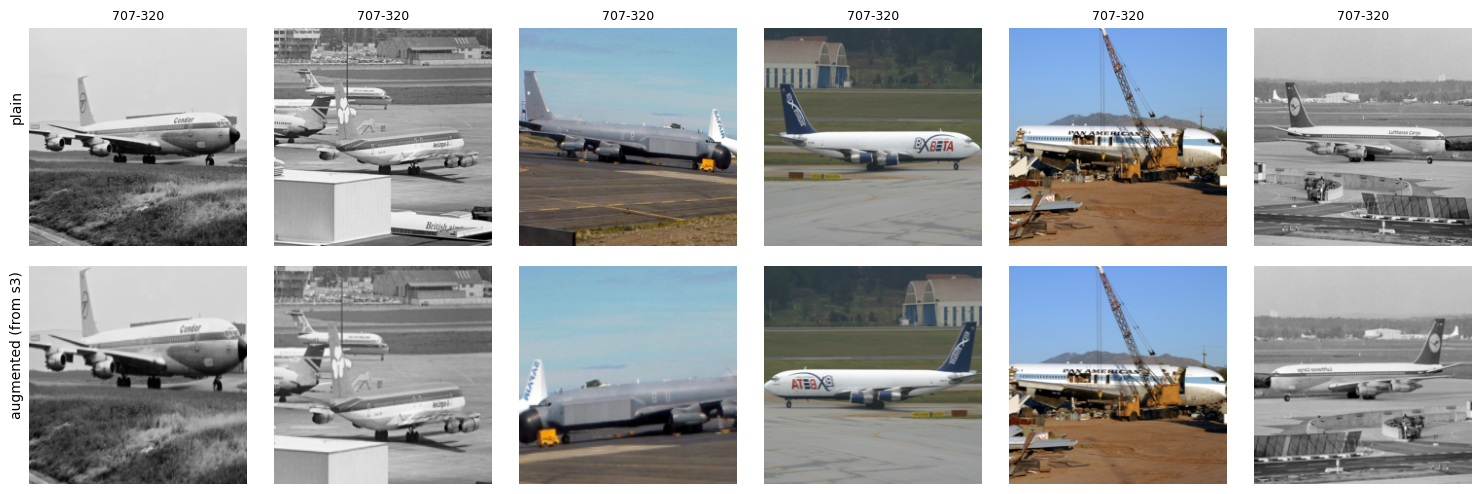

In [10]:
data = get_data(BASE["img_size"])
CLASSES = data["train"].classes
N_CLASSES = len(CLASSES)
print(f"classes: {N_CLASSES} | train {len(data['train'])} | val {len(data['val'])} | test {len(data['test'])}")

fix_random(0)
x = data["train"].x[:6].float() / 255
rows = [x, gpu_augment(x, BASE["img_size"], scale=BASE["crop_scale"])]
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for r, imgs in enumerate(rows):
    for c in range(6):
        axes[r, c].imshow(imgs[c].permute(1, 2, 0).clamp(0, 1).cpu())
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(CLASSES[data["train"].y[c]], fontsize=9)
axes[0, 0].text(-20, 80, "plain", rotation=90, va="center")
axes[1, 0].text(-20, 80, "augmented (from s3)", rotation=90, va="center")
plt.tight_layout(); plt.show()

## The network

A single class covers every configuration:

```
blocks = (n1, n2, n3, n4)

stem      3x3 s2 -> 3x3 -> 3x3 -> maxpool s2          224 -> 56
stage 1   n1 x Block(64)                              56x56
stage 2   n2 x Block(128), the first one stride 2     28x28
stage 3   n3 x Block(256), the first one stride 2     14x14
(stage 4  n4 x Block(512), the first one stride 2      7x7)
head      flatten -> linear            (gap=False)
          global avg pool -> linear    (gap=True)
```

`n x Block(C)` denotes `n` consecutive blocks with `C` output channels. The number of convolutional layers is 3 (stem)
plus 2 per block: 9 for s0–s3, 11 for s4, 19 for `[2,2,2,2]`, 31 for `[3,4,6,1]`.

**Stem.** We reduce the resolution by 4 before the first stage, as in ResNet (He et al., CVPR 2016) and GoogLeNet
(Szegedy et al., CVPR 2015): early layers only detect edges and simple textures, and running the blocks at 56x56
instead of 224x224 is 16 times cheaper. Instead of a single 7x7 convolution we use three 3x3 convolutions with 32, 32
and 64 channels, the "ResNet-C" stem of He et al. (*Bag of Tricks for Image Classification*, CVPR 2019): the same 7x7
receptive field with fewer parameters and two more non-linearities (Simonyan & Zisserman, ICLR 2015). The stem is kept
narrow because it runs at the highest resolution.

**Block.** A block is two 3x3 convolutions, each followed by BatchNorm when enabled. With `residual=True` the block
computes `F(x) + x`: it only has to learn a correction to the identity, and the gradient reaches earlier layers
directly through the skip (He et al., 2016). When a block changes resolution or number of channels, the input goes
through a 1x1 convolution with BN (projection); otherwise it is added unchanged (identity). Plain networks do not
create the projections, so plain and residual versions of a network have almost the same number of parameters.
With one block per stage every skip is a projection; identity skips appear from the second block of a stage on.

In [11]:
def conv_bn(c_in, c_out, k, stride, bn):
    layers = [nn.Conv2d(c_in, c_out, k, stride=stride, padding=k // 2, bias=not bn)]
    if bn:
        layers.append(nn.BatchNorm2d(c_out))
    return nn.Sequential(*layers)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, bn, residual):
        super().__init__()
        self.conv1 = conv_bn(c_in, c_out, 3, stride, bn)
        self.conv2 = conv_bn(c_out, c_out, 3, 1, bn)
        self.residual = residual
        if residual and (stride != 1 or c_in != c_out):
            self.skip = conv_bn(c_in, c_out, 1, stride, bn)      # projection
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        out = self.conv2(F.relu(self.conv1(x)))
        if self.residual:
            out = out + self.skip(x)
        return F.relu(out)


class AircraftNet(nn.Module):
    def __init__(self, cfg, n_classes=100):
        super().__init__()
        bn = cfg["batchnorm"]
        c1, c2, c3 = cfg["stem"]
        self.stem = nn.Sequential(
            conv_bn(3, c1, 3, 2, bn), nn.ReLU(inplace=True),
            conv_bn(c1, c2, 3, 1, bn), nn.ReLU(inplace=True),
            conv_bn(c2, c3, 3, 1, bn), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        layers, c_in = [], c3
        for stage, (c_out, n_blocks) in enumerate(zip(cfg["channels"], cfg["blocks"])):
            for b in range(n_blocks):
                stride = 2 if (b == 0 and stage > 0) else 1
                layers.append(Block(c_in, c_out, stride, bn, cfg["residual"]))
                c_in = c_out
        self.stages = nn.Sequential(*layers)

        if cfg["gap"]:
            self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                      nn.Dropout(cfg["dropout"]), nn.Linear(c_in, n_classes))
        else:
            with torch.no_grad():   # size of the last feature map, for the flatten head
                s = self.stages(self.stem(torch.zeros(1, 3, cfg["img_size"], cfg["img_size"]))).shape
            self.head = nn.Sequential(nn.Flatten(), nn.Dropout(cfg["dropout"]),
                                      nn.Linear(s[1] * s[2] * s[3], n_classes))

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_gflops(model, img_size):
    # Multiply-adds of convolutions and linear layers for one image, x2 = FLOPs.
    macs = 0

    def hook(m, inp, out):
        nonlocal macs
        if isinstance(m, nn.Conv2d):
            macs += out[0].numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        elif isinstance(m, nn.Linear):
            macs += m.in_features * m.out_features

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, img_size, img_size))
    for h in handles:
        h.remove()
    return 2 * macs / 1e9

Layer-by-layer summary of one network (`torchinfo`); a summary is also printed at the start of every run whose
architecture differs from the previous one (`SHOW_SUMMARY`).

In [12]:
# the keys that define the architecture: two runs with the same values build the same network
ARCH_KEYS = ("img_size", "stem", "channels", "blocks", "batchnorm", "gap", "residual", "dropout")


def show_summary(cfg, depth=4):
    return torchinfo.summary(AircraftNet(cfg, N_CLASSES), input_size=(1, 3, cfg["img_size"], cfg["img_size"]),
                             col_names=("output_size", "num_params"), row_settings=("var_names",),
                             depth=depth, device="cpu", verbose=0)


show_summary({**BASE, **dict(GRID)["res_2222"]})

Layer (type (var_name))                  Output Shape              Param #
AircraftNet (AircraftNet)                [1, 100]                  --
├─Sequential (stem)                      [1, 64, 56, 56]           --
│    └─Sequential (0)                    [1, 32, 112, 112]         --
│    │    └─Conv2d (0)                   [1, 32, 112, 112]         864
│    │    └─BatchNorm2d (1)              [1, 32, 112, 112]         64
│    └─ReLU (1)                          [1, 32, 112, 112]         --
│    └─Sequential (2)                    [1, 32, 112, 112]         --
│    │    └─Conv2d (0)                   [1, 32, 112, 112]         9,216
│    │    └─BatchNorm2d (1)              [1, 32, 112, 112]         64
│    └─ReLU (3)                          [1, 32, 112, 112]         --
│    └─Sequential (4)                    [1, 64, 112, 112]         --
│    │    └─Conv2d (0)                   [1, 64, 112, 112]         18,432
│    │    └─BatchNorm2d (1)              [1, 64, 112, 112]         128
│    └

Size and cost of every configuration. `head_share` is the fraction of the parameters in the classifier: with the
flatten head (s0, s1) it holds 81% of the network.

In [13]:
rows = []
for name, over in LADDER + GRID:
    cfg = {**BASE, **over}
    m = AircraftNet(cfg, N_CLASSES)
    head = sum(p.numel() for p in m.head.parameters())
    rows.append(dict(run=name, params_M=count_params(m) / 1e6, head_share=head / count_params(m),
                     GFLOPs=count_gflops(m, cfg["img_size"]), convs=sum(isinstance(l, nn.Conv2d) for l in m.modules())))
pd.DataFrame(rows).set_index("run").style.format({"params_M": "{:.2f}", "head_share": "{:.0%}", "GFLOPs": "{:.2f}"})

,params_M,head_share,GFLOPs,convs
run,,,,
s0_vgg,6.23,81%,1.88,9
s1_bn,6.23,81%,1.88,9
s2_gap,1.24,2%,1.87,9
s3_aug,1.24,2%,1.87,9
s4_stage4,4.80,1%,2.22,11
plain_1111,4.80,1%,2.22,11
res_1111,4.98,1%,2.26,14
plain_2222,11.07,0%,4.07,19
res_2222,11.25,0%,4.11,22


## Training

- **Optimizer**: SGD with momentum 0.9; when enabled, weight decay applies to convolution and linear weights only, not
  to BN parameters and biases.
- **Schedule**: linear warmup for 3 epochs, then cosine decay to zero (or one-cycle, where selected by the tuning).
- **Loss**: cross-entropy (with label smoothing where enabled). The validation loss is always plain cross-entropy, so
  that runs with and without smoothing are on the same scale.
- **Mixed precision** on CUDA (Micikevicius et al., ICLR 2018).
- **Model selection**: we keep the epoch with the highest validation accuracy and evaluate the test split once, on
  that checkpoint.

In [14]:
def autocast():
    return torch.autocast("cuda", dtype=AMP_DTYPE) if AMP else contextlib.nullcontext()


def make_optimizer(model, cfg):
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    return torch.optim.SGD([{"params": decay, "weight_decay": cfg["weight_decay"]},
                            {"params": no_decay, "weight_decay": 0.0}],
                           lr=cfg["lr"], momentum=cfg["momentum"])


def lr_at(epoch, cfg):
    if cfg.get("schedule", "cosine") == "onecycle":
        # one-cycle (Smith & Topin, 2019), per epoch: cosine rise from lr/25 to lr over the first 30% of the
        # epochs, then cosine decay to lr/1e4 (the defaults of torch.optim.lr_scheduler.OneCycleLR)
        up = max(round(0.3 * cfg["epochs"]), 1)
        low, high, end = cfg["lr"] / 25, cfg["lr"], cfg["lr"] / 1e4
        if epoch < up:
            return high + (low - high) * (1 + math.cos(math.pi * epoch / up)) / 2
        t = (epoch - up) / max(cfg["epochs"] - up, 1)
        return end + (high - end) * (1 + math.cos(math.pi * t)) / 2
    if epoch < cfg["warmup_epochs"]:
        return cfg["lr"] * (epoch + 1) / cfg["warmup_epochs"]
    progress = (epoch - cfg["warmup_epochs"]) / max(cfg["epochs"] - cfg["warmup_epochs"], 1)
    return cfg["lr"] * 0.5 * (1 + math.cos(math.pi * progress))


def train_epoch(model, opt, scaler, criterion, data, cfg):
    model.train()
    total_loss = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    n = 0
    for x, y in batches(data["train"], data, cfg, train=True):
        with autocast():
            logits = model(x)
            loss = criterion(logits, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total_loss += loss.detach().float() * len(y)
        correct += (logits.argmax(1) == y).sum()
        n += len(y)
    return total_loss.item() / n, correct.item() / n


@torch.no_grad()
def evaluate(model, split, data, cfg, return_preds=False):
    model.eval()
    total_loss, correct, preds = 0.0, 0, []
    for x, y in batches(split, data, cfg, train=False):
        with autocast():
            logits = model(x)
        total_loss += F.cross_entropy(logits.float(), y, reduction="sum").item()
        p = logits.argmax(1)
        correct += (p == y).sum().item()
        if return_preds:
            preds.append(p.cpu())
    n = len(split)
    out = (total_loss / n, correct / n)
    return out + (torch.cat(preds).tolist(),) if return_preds else out


def fit(cfg, data, verbose=True):
    model = AircraftNet(cfg, N_CLASSES).to(DEVICE).to(memory_format=torch.channels_last)
    opt = make_optimizer(model, cfg)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP and AMP_DTYPE == torch.float16)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "lr", "seconds")}
    best_acc, best_epoch, best_state, diverged = -1.0, 0, None, False

    for epoch in range(cfg["epochs"]):
        t0 = time.time()
        lr = lr_at(epoch, cfg)
        for g in opt.param_groups:
            g["lr"] = lr
        tr_loss, tr_acc = train_epoch(model, opt, scaler, criterion, data, cfg)
        if not math.isfinite(tr_loss):
            diverged = True
            print(f"  diverged at epoch {epoch + 1} (training loss {tr_loss})")
            break
        va_loss, va_acc = evaluate(model, data["val"], data, cfg)
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc, lr, time.time() - t0)):
            hist[k].append(v)
        if va_acc > best_acc:
            best_acc, best_epoch = va_acc, epoch + 1
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose and (epoch % 5 == 0 or epoch == cfg["epochs"] - 1):
            print(f"  ep {epoch + 1:3d} | lr {lr:.4f} | train loss {tr_loss:.3f} acc {tr_acc:.3f} "
                  f"| val loss {va_loss:.3f} acc {va_acc:.3f} | {hist['seconds'][-1]:.1f}s")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, hist, best_epoch, diverged

### Sanity checks

At initialization the loss must be close to ln(100) ≈ 4.61 (a uniform guess over 100 classes), and the network must be
able to memorize 100 training images; otherwise the data, the labels or the training step are wrong.

In [15]:
fix_random(0)
cfg = {**BASE, "batchnorm": True}
model = AircraftNet(cfg, N_CLASSES).to(DEVICE)
x, y = next(batches(data["train"], data, cfg, train=True))
with torch.no_grad():
    print(f"initial loss {F.cross_entropy(model(x), y).item():.3f}  (expected ~{math.log(N_CLASSES):.2f})")

# memorize 100 images with Adam, full batch
idx = torch.arange(100, device=DEVICE)
x = ((data["train"].x[idx].float() / 255 - data["mean"]) / data["std"])
y = data["train"].y[idx]
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
for step in range(150):
    loss = F.cross_entropy(model(x), y)
    opt.zero_grad(); loss.backward(); opt.step()
model.eval()
with torch.no_grad():
    print(f"tiny subset: train acc {(model(x).argmax(1) == y).float().mean().item():.2f}  (expected ~1.00)")

initial loss 4.665  (expected ~4.61)
tiny subset: train acc 1.00  (expected ~1.00)


## Experiment runner

`run_experiment` trains one configuration, evaluates its best checkpoint on the test split and stores the
configuration, the per-epoch curves and the test predictions. `run_sweep` trains a configuration at every learning
rate of the sweep (seed 42); `run_seeds` trains it with two more seeds at its best learning rate. Note that the seed-42
run of a configuration is the best of three learning rates, hence slightly optimistic; the two additional seeds are
not.

In [16]:
def result_path(name, group, seed):
    return RESULTS_DIR / group / f"{name}_seed{seed}.json"


_last_arch = None


def run_experiment(name, group, note="", **overrides):
    global _last_arch
    cfg = {**BASE, **overrides, "name": name, "group": group}
    out = result_path(name, group, cfg["seed"])
    if out.exists() and not RETRAIN:
        run = json.loads(out.read_text())
        if run["config"] == json.loads(json.dumps(cfg)):      # same configuration (tuples stored as lists)
            print(f"skip {group}/{name}: best val {run['best_val_acc']:.3f} (already trained)")
            return run
        print(f"{group}/{name}: configuration changed since the stored run, training again")

    print(f"### {group}/{name}")
    print("    " + " | ".join(f"{k} {cfg[k]}" for k in ("lr", "weight_decay", "label_smoothing", "dropout",
                                                        "random_erasing", "augment", "crop_scale", "seed", "epochs"))
          + f" | schedule {cfg.get('schedule', 'cosine')}")
    arch = {k: cfg[k] for k in ARCH_KEYS}
    if SHOW_SUMMARY and arch != _last_arch:
        print(show_summary(cfg))
        _last_arch = arch
    fix_random(cfg["seed"])
    data = get_data(cfg["img_size"])
    t0 = time.time()
    model, hist, best_epoch, diverged = fit(cfg, data)
    minutes = (time.time() - t0) / 60
    if best_epoch:
        test_loss, test_acc, test_pred = evaluate(model, data["test"], data, cfg, return_preds=True)
    else:   # diverged before the first validation: there is no checkpoint to test
        test_loss, test_acc, test_pred = float("nan"), float("nan"), []

    cpu_model = AircraftNet(cfg, N_CLASSES)
    run = dict(
        name=name, group=group, seed=cfg["seed"], note=note, config=cfg, history=hist,
        best_val_acc=max(hist["val_acc"], default=0.0), best_epoch=best_epoch,
        final_val_acc=hist["val_acc"][-1] if hist["val_acc"] else 0.0,
        final_train_acc=hist["train_acc"][-1] if hist["train_acc"] else 0.0,
        test_acc=test_acc, test_loss=test_loss, test_pred=test_pred,
        test_true=data["test"].y.cpu().tolist(),
        params=count_params(cpu_model), gflops=count_gflops(cpu_model, cfg["img_size"]),
        minutes=minutes, device=torch.cuda.get_device_name() if AMP else str(DEVICE), diverged=diverged,
    )
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text(json.dumps(run))
    print(f"{name}: best val {run['best_val_acc']:.3f} (epoch {best_epoch}) | test {test_acc:.3f} | {minutes:.1f} min")
    return run


def load_group(group):
    runs = [json.loads(p.read_text()) for p in sorted((RESULTS_DIR / group).glob("*.json"))]
    return {r["name"]: r for r in runs}


def sweep_runs(runs, name):
    # The seed-42 runs of one configuration of the sweep, keyed by learning rate.
    return {r["config"]["lr"]: r for n, r in runs.items()
            if n.startswith(f"{name}_lr") and r["config"]["lr"] in LR_SWEEP and r["seed"] == SEEDS[0]}


def best_of(runs, name):
    # The best run (on validation) of one configuration of the sweep; None until every learning rate is trained.
    swept = sweep_runs(runs, name)
    if len(swept) < len(LR_SWEEP):
        return None
    return max(swept.values(), key=lambda r: r["best_val_acc"])


def run_sweep(name, group, note="", **overrides):
    for lr in LR_SWEEP:
        run_experiment(f"{name}_lr{lr:g}", group, note=note, **{**overrides, "lr": lr})
    best = best_of(load_group(group), name)
    print(f"==> {name}: best lr {best['config']['lr']:g} | val {best['best_val_acc']:.3f} | test {best['test_acc']:.3f}\n")
    return best


def run_seeds(name, group, note="", **overrides):
    # The other seeds, at the learning rate that won the sweep of this configuration.
    lr = best_of(load_group(group), name)["config"]["lr"]
    for seed in SEEDS[1:]:
        run_experiment(f"{name}_lr{lr:g}_s{seed}", f"{group}_seeds", note=note, seed=seed, **{**overrides, "lr": lr})


def seed_runs(name, group):
    # Every seed of one configuration at its best learning rate: [seed 42 (from the sweep), seed 43, seed 44].
    best = best_of(load_group(group), name)
    if best is None:
        return []
    lr, others = best["config"]["lr"], load_group(f"{group}_seeds")
    return [best] + [others[f"{name}_lr{lr:g}_s{s}"] for s in SEEDS[1:] if f"{name}_lr{lr:g}_s{s}" in others]


def seed_mean(runs, key="best_val_acc"):
    return float(np.mean([r[key] for r in runs]))


def seed_std(runs, key="best_val_acc"):
    return float(np.std([r[key] for r in runs], ddof=1)) if len(runs) > 1 else float("nan")


def finalists(n=TUNE_N):
    # The n networks of the grid with the highest mean validation accuracy over the seeds.
    done = {name: seed_runs(name, "depth_residual") for name, _ in GRID}
    if any(len(r) < len(SEEDS) for r in done.values()):
        return None
    return sorted(done, key=lambda name: -seed_mean(done[name]))[:n]


def simplicity(name):
    # Sort key: fewer blocks first, then plain before residual.
    over = dict(GRID)[name]
    return (sum(over["blocks"]), over["residual"])


def random_configs():
    # The N_RANDOM configurations of the random search: drawn once, identical for every network.
    rng = np.random.RandomState(SEARCH_SEED)
    configs, seen = [], set()
    while len(configs) < N_RANDOM:
        cfg = {k: v[rng.randint(len(v))] for k, v in SEARCH_SPACE.items()}
        key = json.dumps(cfg)
        if key not in seen:
            seen.add(key)
            if cfg["schedule"] == "cosine":
                del cfg["schedule"]            # cosine is the default: keep the stored config minimal
            configs.append(cfg)
    return configs


def run_overrides(run):
    # The overrides that reproduce a stored run (everything but its name, group and seed).
    return {k: v for k, v in run["config"].items() if k not in ("name", "group", "seed")}


def tuning_runs(name):
    # Every seed-42 run of the recipe search (grid + random) of one network, keyed by run name.
    runs = {**load_group("tune_grid"), **load_group("tune_random")}
    return {n: r for n, r in runs.items() if n.startswith(name + "_")}


def best_grid_point(name):
    grid = {n: r for n, r in load_group("tune_grid").items() if n.startswith(name + "_")}
    if len(grid) < len(TUNE_LRS) * len(TUNE_WDS):
        return None
    best = max(grid.values(), key=lambda r: r["best_val_acc"])
    return best["config"]["lr"], best["config"]["weight_decay"]


def top_configs(name):
    # The TOP_K best runs of the search of one network (seed 42).
    runs = tuning_runs(name)
    return sorted(runs.values(), key=lambda r: -r["best_val_acc"])[:TOP_K]


def confirmed(name):
    # {run name: [seed 42, 43, 44]} for the TOP_K configurations of one network.
    seeds = load_group("tune_seeds")
    return {r["name"]: [r] + [seeds[f"{r['name']}_s{s}"] for s in SEEDS[1:] if f"{r['name']}_s{s}" in seeds]
            for r in top_configs(name)}

### Timing

Two epochs of the cheapest and of the most expensive network, and the resulting estimate for the whole notebook.

In [17]:
# [run]
per_epoch = {}
for name, over in [("s0_vgg", {}), ("res_3461", dict(GRID)["res_3461"])]:
    cfg = {**BASE, **over, "epochs": 2, "warmup_epochs": 1, "lr": 0.01}
    fix_random(0)
    _, hist, _, _ = fit(cfg, data, verbose=False)
    per_epoch[name] = sum(hist["seconds"]) / len(hist["seconds"])
    print(f"{name:10s} {per_epoch[name]:5.1f} s/epoch -> {per_epoch[name] * BASE['epochs'] / 60:5.1f} min per run")

n_small = len(LADDER) * len(LR_SWEEP)
n_big = (len(GRID) * (len(LR_SWEEP) + len(SEEDS) - 1)
         + TUNE_N * (len(TUNE_LRS) * len(TUNE_WDS) + N_RANDOM + TOP_K * (len(SEEDS) - 1)))
total = (n_small * per_epoch["s0_vgg"] + n_big * per_epoch["res_3461"]) * BASE["epochs"] / 60
print(f"{n_small + n_big} runs, at most ~{total:.0f} min in total")

s0_vgg      30.3 s/epoch ->  35.3 min per run
res_3461    81.4 s/epoch ->  94.9 min per run
139 runs, at most ~12303 min in total


## The ladder: s0 -> s4

What each step is expected to show:

- **s0 (plain VGG) memorizes.** It has 6.2M parameters for 3,334 training images, 5M of them in the flatten head: the
  last feature map is flattened into 50,176 features, more than the number of training images, so a linear classifier
  on top can separate any labelling of them. With no augmentation and no regularization, training accuracy reaches
  100% while validation accuracy stalls and validation loss rises. Standard CNNs can even fit randomly shuffled labels
  (Zhang et al., ICLR 2017).
- **s1, BatchNorm** (Ioffe & Szegedy, ICML 2015) normalizes the activations of every layer, which makes optimization
  better behaved and more tolerant to the learning rate.
- **s2, global average pooling** (Lin et al., *Network in Network*, ICLR 2014) reduces each channel of the last
  feature map to one number: the 5M-weight head becomes a 26k-weight one.
- **s3, crop and flip** show a different version of every image at every epoch, so the training set can no longer be
  memorized exactly.
- **s4, a 4th stage** adds capacity and receptive field once the network is regularized.

In [18]:
# [run]
for name, over in LADDER:
    run_sweep(name, "ladder", **over)

skip ladder/s0_vgg_lr0.1: best val 0.021 (already trained)
skip ladder/s0_vgg_lr0.05: best val 0.040 (already trained)
skip ladder/s0_vgg_lr0.01: best val 0.185 (already trained)
==> s0_vgg: best lr 0.01 | val 0.185 | test 0.189

skip ladder/s1_bn_lr0.1: best val 0.097 (already trained)
skip ladder/s1_bn_lr0.05: best val 0.133 (already trained)
skip ladder/s1_bn_lr0.01: best val 0.302 (already trained)
==> s1_bn: best lr 0.01 | val 0.302 | test 0.299

skip ladder/s2_gap_lr0.1: best val 0.435 (already trained)
skip ladder/s2_gap_lr0.05: best val 0.405 (already trained)
skip ladder/s2_gap_lr0.01: best val 0.242 (already trained)
==> s2_gap: best lr 0.1 | val 0.435 | test 0.440

skip ladder/s3_aug_lr0.1: best val 0.477 (already trained)
skip ladder/s3_aug_lr0.05: best val 0.463 (already trained)
skip ladder/s3_aug_lr0.01: best val 0.227 (already trained)
==> s3_aug: best lr 0.1 | val 0.477 | test 0.477

skip ladder/s4_stage4_lr0.1: best val 0.515 (already trained)
skip ladder/s4_stage4_lr

## Depth x residual

We replicate at small scale the central experiment of He et al. (CVPR 2016): **identical plain and residual networks
at increasing depth**. All six networks are s4 (BatchNorm, GAP, crop and flip, four stages of 64 to 512 channels) with
a different number of blocks per stage, with and without skip connections:

| blocks per stage | convolutional layers | parameters | motivation |
|---|---|---|---|
| `[1,1,1,1]` | 11 | 4.8M | s4 itself, the shallow reference |
| `[2,2,2,2]` | 19 | 11.1M | the stage layout of ResNet-18; at this depth He et al. find plain and residual networks on par |
| `[3,4,6,1]` | 31 | 11.8M | the layout of ResNet-34 with a single block in the last stage; at 34 layers He et al. find the plain network *worse* than its shallower version and the residual one better |

We use `[3,4,6,1]` rather than the full `[3,4,6,3]` (21.4M parameters) because a 512-channel block alone costs 4.7M
parameters: the additional depth goes into the first three stages, where it is cheap.

**Reading the results.** Within a depth, plain and residual networks differ only by the skip connections. Across
depths more changes than depth (`[3,4,6,1]` also redistributes capacity and doubles the compute), so a drop of the
plain network with depth is meaningful only if the residual network with the same layout does not drop. The
signature of degradation is in the *training* accuracy: a network that is harder to optimize fits its training set
worse, whereas an overfitting one fits it better.

In [19]:
# [run]
for name, over in GRID:
    run_sweep(name, "depth_residual", **over)

skip depth_residual/plain_1111_lr0.1: best val 0.515 (already trained)
skip depth_residual/plain_1111_lr0.05: best val 0.526 (already trained)
skip depth_residual/plain_1111_lr0.01: best val 0.395 (already trained)
==> plain_1111: best lr 0.05 | val 0.526 | test 0.507

skip depth_residual/res_1111_lr0.1: best val 0.470 (already trained)
skip depth_residual/res_1111_lr0.05: best val 0.456 (already trained)
skip depth_residual/res_1111_lr0.01: best val 0.291 (already trained)
==> res_1111: best lr 0.1 | val 0.470 | test 0.465

skip depth_residual/plain_2222_lr0.1: best val 0.533 (already trained)
skip depth_residual/plain_2222_lr0.05: best val 0.557 (already trained)
skip depth_residual/plain_2222_lr0.01: best val 0.509 (already trained)
==> plain_2222: best lr 0.05 | val 0.557 | test 0.545

skip depth_residual/res_2222_lr0.1: best val 0.532 (already trained)
skip depth_residual/res_2222_lr0.05: best val 0.534 (already trained)
skip depth_residual/res_2222_lr0.01: best val 0.420 (already

### Seeds

Run-to-run variation (initialization, data order, augmentation) is easily 1–2 points on 3,333 validation images,
comparable to the differences between several networks. We train every network with two more seeds at its best
learning rate and compare means.

In [20]:
# [run]
for name, over in GRID:
    run_seeds(name, "depth_residual", note="seeds", **over)

skip depth_residual_seeds/plain_1111_lr0.05_s43: best val 0.506 (already trained)
skip depth_residual_seeds/plain_1111_lr0.05_s44: best val 0.507 (already trained)
skip depth_residual_seeds/res_1111_lr0.1_s43: best val 0.472 (already trained)
skip depth_residual_seeds/res_1111_lr0.1_s44: best val 0.465 (already trained)
skip depth_residual_seeds/plain_2222_lr0.05_s43: best val 0.574 (already trained)
skip depth_residual_seeds/plain_2222_lr0.05_s44: best val 0.546 (already trained)
skip depth_residual_seeds/res_2222_lr0.05_s43: best val 0.521 (already trained)
skip depth_residual_seeds/res_2222_lr0.05_s44: best val 0.510 (already trained)
skip depth_residual_seeds/plain_3461_lr0.01_s43: best val 0.467 (already trained)
skip depth_residual_seeds/plain_3461_lr0.01_s44: best val 0.492 (already trained)
skip depth_residual_seeds/res_3461_lr0.05_s43: best val 0.544 (already trained)
skip depth_residual_seeds/res_3461_lr0.05_s44: best val 0.545 (already trained)


## The training recipe

We now regularize the three best networks of the depth x residual experiment and tune their training recipe. The
recipe combines standard techniques from lecture 6:

| component | effect | reference |
|---|---|---|
| weight decay (not on BN/bias) | penalizes large weights | l2 regularization, lecture 6 |
| label smoothing | target of 1−ε on the true class, ε spread over the others: the network is not pushed towards infinite confidence | Szegedy et al., CVPR 2016 |
| dropout before the classifier | randomly drops features during training; placed between global pooling and the last linear layer | Srivastava et al., JMLR 2014 |
| random erasing | hides a random rectangle of the image | Zhong et al., AAAI 2020 |
| minimum crop area | smaller crops show parts of the aircraft at a larger scale (multi-scale training) | lecture 6 |
| one-cycle schedule | the learning rate rises over the first 30% of training, then decays | Smith & Topin, 2019 |

We tune it in three steps, following the hyperparameter search of lecture 6:

1. **Grid search on learning rate x weight decay** (log-spaced), the two most influential parameters: learning rate
   0.1 and 0.05, weight decay from 1e-4 to 1e-2. During this step the other parameters are fixed (label smoothing
   0.1, dropout 0.2, random erasing 0.25, minimum crop 50%, cosine schedule). The grid initially stopped at 2e-3,
   which turned out to be the best value for two networks; since an optimum at the edge of a grid may lie beyond it,
   we extended the grid until accuracy decreased.
2. **Random search on the other parameters** (Bergstra & Bengio, JMLR 2012), at the best learning rate and weight
   decay of each network. A full grid on these five parameters would require 216 runs per network; we draw 12
   configurations once and train the same 12 on every network.
3. **Confirmation with seeds.** The best of many single runs is partly the luckiest one, so we retrain the two best
   configurations of each network with two more seeds and compare means.

| parameter | values | note |
|---|---|---|
| label smoothing | 0, 0.05, 0.1, 0.2 | |
| dropout | 0, 0.2, 0.5 | dropout is not used in ResNets, for its unclear interaction with BatchNorm (lecture 6), so 0 is a real candidate |
| random erasing | p = 0, 0.25, 0.5 | the original papers use 0.5 |
| minimum crop area | 25%, 35%, 50% | |
| schedule | cosine with warmup, one-cycle | |

We leave out Mixup, CutMix, TrivialAugment and stochastic depth, which make the training task much harder and pay off
only with schedules much longer than 70 epochs, and the exponential moving average of the weights, which mainly helps
at the end of long trainings: they are candidates for a final, longer training.

**Networks.** We tune `plain_2222` and `res_3461`, the two best networks, and `res_2222`, the third: it has the
highest training accuracy of the experiment, i.e. it overfits the most, so it is the network a stronger regularization
can help most. We exclude `plain_3461`, which does not fit its training set (an optimization problem that
regularization cannot fix), and the two 11-layer networks, which trail the best ones by 5–9 points. All three networks
receive the same tuning budget, so that the final comparison is fair.

**Selection rule.** For each network we take its best configuration by mean validation accuracy over the seeds; the
final network is the one with the highest mean, and if the two best are within one standard deviation of each other,
the simpler one.

**Limitation.** The search proceeds in two stages: the learning rate and weight decay are chosen with fixed values of
the other parameters, so they are not guaranteed to be jointly optimal with the configuration found by the random
search.

In [22]:
# [run]
names = finalists(TUNE_N)
if names is None:
    print("train the whole grid with all its seeds first")
else:
    print("networks:", names)
    # 1. grid search: learning rate x weight decay, the other parameters as in RECIPE
    for name in names:
        for lr in TUNE_LRS:
            for wd in TUNE_WDS:
                run_experiment(f"{name}_lr{lr:g}_wd{wd:g}", "tune_grid", note="tuning: lr x wd",
                               **{**dict(GRID)[name], **RECIPE, "lr": lr, "weight_decay": wd})
        lr, wd = best_grid_point(name)
        print(f"==> {name}: best lr {lr:g}, weight decay {wd:g}\n")

networks: ['plain_2222', 'res_3461', 'res_2222']
skip tune_grid/plain_2222_lr0.1_wd0.0001: best val 0.570 (already trained)
skip tune_grid/plain_2222_lr0.1_wd0.0005: best val 0.560 (already trained)
skip tune_grid/plain_2222_lr0.1_wd0.001: best val 0.562 (already trained)
skip tune_grid/plain_2222_lr0.1_wd0.002: best val 0.525 (already trained)
skip tune_grid/plain_2222_lr0.1_wd0.005: best val 0.422 (already trained)
skip tune_grid/plain_2222_lr0.1_wd0.01: best val 0.240 (already trained)
skip tune_grid/plain_2222_lr0.05_wd0.0001: best val 0.568 (already trained)
skip tune_grid/plain_2222_lr0.05_wd0.0005: best val 0.597 (already trained)
skip tune_grid/plain_2222_lr0.05_wd0.001: best val 0.604 (already trained)
skip tune_grid/plain_2222_lr0.05_wd0.002: best val 0.610 (already trained)
skip tune_grid/plain_2222_lr0.05_wd0.005: best val 0.551 (already trained)
skip tune_grid/plain_2222_lr0.05_wd0.01: best val 0.447 (already trained)
==> plain_2222: best lr 0.05, weight decay 0.002

skip 

In [23]:
# [run]
# 2. random search on the other parameters, at the best lr and weight decay of each network
configs = random_configs()
for i, c in enumerate(configs):
    print(f"cfg{i:02d}  {c}")
for name in finalists(TUNE_N):
    lr, wd = best_grid_point(name)
    for i, c in enumerate(configs):
        run_experiment(f"{name}_cfg{i:02d}", "tune_random", note="tuning: random search",
                       **{**dict(GRID)[name], **RECIPE, "lr": lr, "weight_decay": wd, **c})

cfg00  {'label_smoothing': 0.0, 'dropout': 0.2, 'random_erasing': 0.0, 'crop_scale': (0.35, 1.0), 'schedule': 'onecycle'}
cfg01  {'label_smoothing': 0.05, 'dropout': 0.5, 'random_erasing': 0.0, 'crop_scale': (0.5, 1.0)}
cfg02  {'label_smoothing': 0.0, 'dropout': 0.0, 'random_erasing': 0.5, 'crop_scale': (0.35, 1.0)}
cfg03  {'label_smoothing': 0.2, 'dropout': 0.5, 'random_erasing': 0.0, 'crop_scale': (0.35, 1.0), 'schedule': 'onecycle'}
cfg04  {'label_smoothing': 0.05, 'dropout': 0.2, 'random_erasing': 0.0, 'crop_scale': (0.35, 1.0)}
cfg05  {'label_smoothing': 0.2, 'dropout': 0.0, 'random_erasing': 0.25, 'crop_scale': (0.5, 1.0), 'schedule': 'onecycle'}
cfg06  {'label_smoothing': 0.2, 'dropout': 0.0, 'random_erasing': 0.5, 'crop_scale': (0.25, 1.0), 'schedule': 'onecycle'}
cfg07  {'label_smoothing': 0.2, 'dropout': 0.2, 'random_erasing': 0.5, 'crop_scale': (0.25, 1.0), 'schedule': 'onecycle'}
cfg08  {'label_smoothing': 0.05, 'dropout': 0.2, 'random_erasing': 0.0, 'crop_scale': (0.5, 1.0

In [24]:
# [run]
# 3. confirmation: the TOP_K best configurations of each network, with the other seeds
for name in finalists(TUNE_N):
    for run in top_configs(name):
        for seed in SEEDS[1:]:
            run_experiment(f"{run['name']}_s{seed}", "tune_seeds", note="tuning: seeds",
                           **{**run_overrides(run), "seed": seed})

skip tune_seeds/plain_2222_cfg05_s43: best val 0.633 (already trained)
skip tune_seeds/plain_2222_cfg05_s44: best val 0.638 (already trained)
skip tune_seeds/plain_2222_cfg11_s43: best val 0.605 (already trained)
skip tune_seeds/plain_2222_cfg11_s44: best val 0.603 (already trained)
skip tune_seeds/res_3461_cfg11_s43: best val 0.628 (already trained)
skip tune_seeds/res_3461_cfg11_s44: best val 0.636 (already trained)
skip tune_seeds/res_3461_cfg05_s43: best val 0.643 (already trained)
skip tune_seeds/res_3461_cfg05_s44: best val 0.639 (already trained)
skip tune_seeds/res_2222_cfg05_s43: best val 0.634 (already trained)
skip tune_seeds/res_2222_cfg05_s44: best val 0.644 (already trained)
skip tune_seeds/res_2222_cfg08_s43: best val 0.626 (already trained)
skip tune_seeds/res_2222_cfg08_s44: best val 0.628 (already trained)


## Results

All tables and plots below are computed from the stored runs.

In [25]:
# Categorical colours in a fixed order (one per run inside a plot)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=COLORS), "lines.linewidth": 2,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def summary(runs):
    # One row per run (single seed).
    rows = [dict(run=n, lr=r["config"]["lr"], params_M=r["params"] / 1e6, best_val=r["best_val_acc"],
                 best_epoch=r["best_epoch"], final_train=r["final_train_acc"],
                 gap=r["final_train_acc"] - r["final_val_acc"], test=r["test_acc"], minutes=r["minutes"])
            for n, r in runs.items()]
    return pd.DataFrame(rows).set_index("run").style.format(
        {"lr": "{:g}", "params_M": "{:.2f}", "best_val": "{:.3f}", "final_train": "{:.3f}", "gap": "{:+.3f}",
         "test": "{:.3f}", "minutes": "{:.1f}"})


def seed_summary(groups):
    # One row per configuration, mean ± std over the seeds. groups: {label: [runs]}
    rows = [dict(run=label, lr=runs[0]["config"]["lr"], seeds=len(runs), params_M=runs[0]["params"] / 1e6,
                 val_mean=seed_mean(runs), val_std=seed_std(runs),
                 test_mean=seed_mean(runs, "test_acc"), test_std=seed_std(runs, "test_acc"),
                 train_mean=seed_mean(runs, "final_train_acc"))
            for label, runs in groups.items() if runs]
    return pd.DataFrame(rows).set_index("run").style.format(
        {"lr": "{:g}", "params_M": "{:.2f}", "val_mean": "{:.3f}", "val_std": "{:.3f}", "test_mean": "{:.3f}",
         "test_std": "{:.3f}", "train_mean": "{:.3f}"})


def plot_curves(runs, title=""):
    # Validation accuracy, validation loss (plain CE) and training accuracy against the epoch.
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for i, (name, r) in enumerate(runs.items()):
        h = r["history"]
        ep = range(1, len(h["val_acc"]) + 1)
        c = COLORS[i % len(COLORS)]
        axes[0].plot(ep, h["val_acc"], color=c, label=name)
        if r["best_epoch"]:
            axes[0].plot(r["best_epoch"], r["best_val_acc"], "o", color=c, markersize=7)
        axes[1].plot(ep, h["val_loss"], color=c, label=name)
        axes[2].plot(ep, h["train_acc"], color=c, label=name)
    for ax, t in zip(axes, ("validation accuracy (dot = best epoch)", "validation loss (plain CE)",
                            "training accuracy")):
        ax.set_title(t); ax.set_xlabel("epoch")
    axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

### The ladder

Each step at its best learning rate (one seed).

Every step improves validation accuracy, from **18.5%** (s0) to **52.6%** (s4): BatchNorm adds 11.7 points, global
average pooling 13.3, crop and flip 4.2, the fourth stage 4.9. The curves show the mechanism: s0–s2 reach 100%
training accuracy, i.e. they memorize the training set, and the validation loss of s0 rises while its training loss
goes to zero. From s3 on, augmentation keeps the training accuracy below 100% and the train–validation gap shrinks.

,lr,params_M,best_val,best_epoch,final_train,gap,test,minutes
run,,,,,,,,
s0_vgg,0.01,6.23,0.185,29,1.000,+0.815,0.189,0.6
s1_bn,0.01,6.23,0.302,37,1.000,+0.699,0.299,0.7
s2_gap,0.1,1.24,0.435,46,1.000,+0.567,0.440,0.7
s3_aug,0.1,1.24,0.477,66,0.947,+0.472,0.477,0.7
s4_stage4,0.05,4.80,0.526,70,0.980,+0.454,0.507,0.8


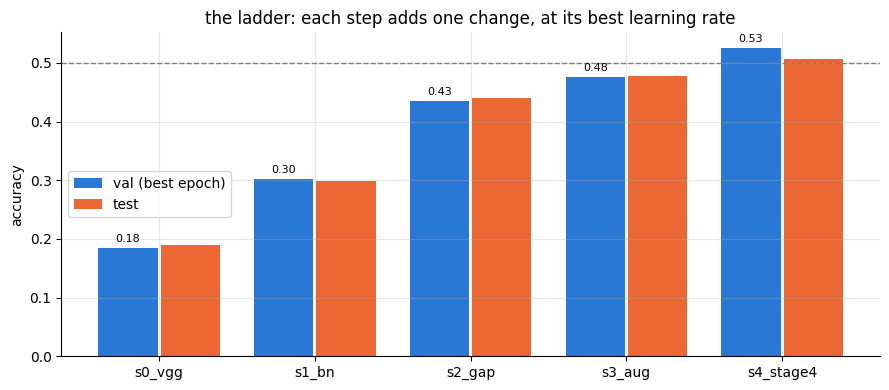

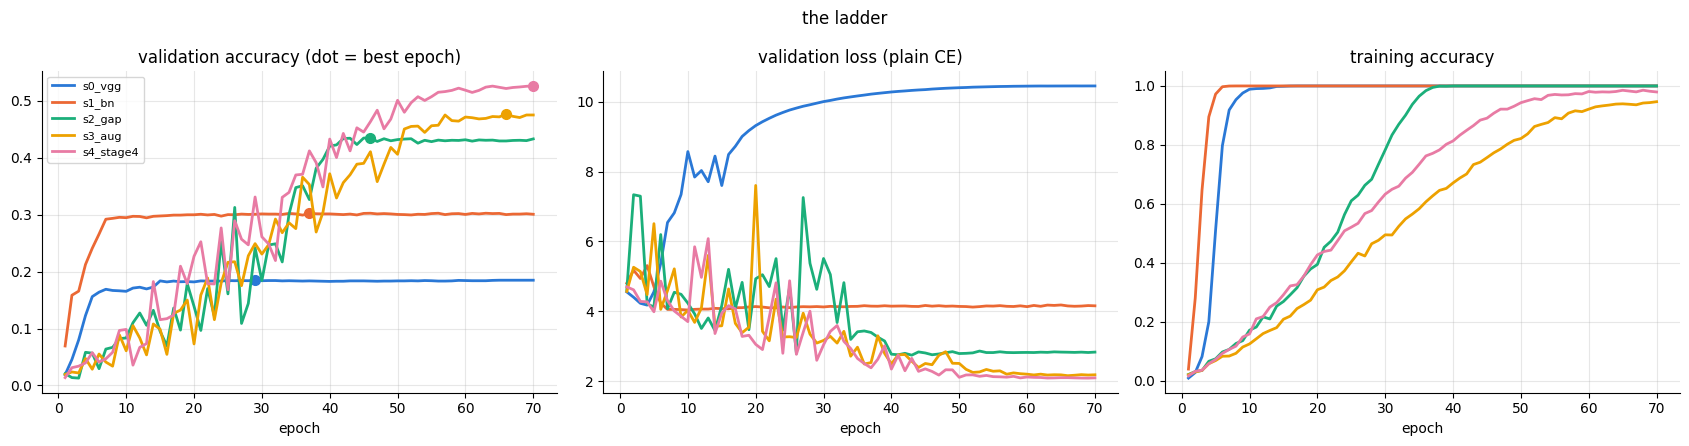

In [26]:
ladder = load_group("ladder")
steps = {n: best_of(ladder, n) for n, _ in LADDER}
steps = {n: r for n, r in steps.items() if r}
if steps:
    display(summary(steps))

    names = list(steps)
    xs = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(xs - 0.2, [steps[n]["best_val_acc"] for n in names], 0.38, label="val (best epoch)", color=COLORS[0])
    ax.bar(xs + 0.2, [steps[n]["test_acc"] for n in names], 0.38, label="test", color=COLORS[1])
    for x_, n in zip(xs, names):
        ax.text(x_ - 0.2, steps[n]["best_val_acc"] + 0.01, f"{steps[n]['best_val_acc']:.2f}", ha="center", fontsize=8)
    ax.set_xticks(xs, names); ax.set_ylabel("accuracy"); ax.axhline(0.5, ls="--", c="gray", lw=1)
    ax.legend(); ax.set_title("the ladder: each step adds one change, at its best learning rate")
    plt.tight_layout(); plt.show()

    plot_curves(steps, "the ladder")

### Sensitivity to the learning rate

Without BatchNorm (s0) the network diverges at lr 0.1 and reaches only 4% at 0.05; with BatchNorm (s1) it trains at
every learning rate and is 11.7 points better at its best one (0.01). After global average pooling the best learning
rate moves to 0.05–0.1 and 0.01 becomes clearly worse: a single learning rate for every step would have penalized
some steps.

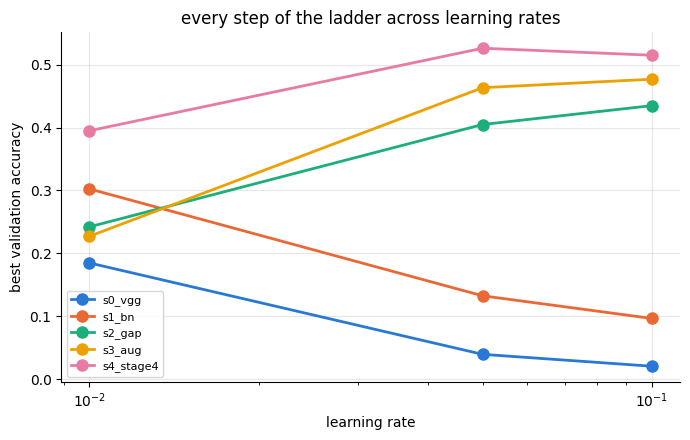

In [27]:
if ladder:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, (name, _) in enumerate(LADDER):
        swept = sweep_runs(ladder, name)
        if swept:
            lrs = sorted(swept)
            ax.plot(lrs, [swept[lr]["best_val_acc"] for lr in lrs], "o-", color=COLORS[i], label=name, markersize=8)
    ax.set_xscale("log"); ax.set_xlabel("learning rate"); ax.set_ylabel("best validation accuracy")
    ax.set_title("every step of the ladder across learning rates"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

### Depth x residual

Mean ± standard deviation over three seeds, each network at its best learning rate; the curves are the seed-42 runs.

- **Degradation.** Going from 19 to 31 layers, the plain network loses 8.3 points (55.9% -> 47.6%) and its *training*
  accuracy drops too (97.5% -> 91.9%): the deeper plain network is harder to optimize, the degradation problem of He et
  al. The residual network improves with depth at every step (46.9% -> 52.2% -> 54.6%) and keeps fitting its training
  set.
- **Shallow networks.** At 11 and 19 layers the residual networks are about 4 points *worse* than the plain ones,
  well beyond the seed noise. They also reach a higher training accuracy (99% vs 97–98%): without regularization, the
  ease of fitting that skip connections provide turns into more overfitting on 33 images per class. The training
  recipe below tests this hypothesis.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
plain_1111,0.05,3,4.80,0.513,0.011,0.501,0.014,0.984
res_1111,0.1,3,4.98,0.469,0.004,0.460,0.004,0.994
plain_2222,0.05,3,11.07,0.559,0.014,0.551,0.012,0.975
res_2222,0.05,3,11.25,0.522,0.012,0.519,0.003,0.991
plain_3461,0.01,3,11.74,0.476,0.014,0.482,0.013,0.919
res_3461,0.05,3,11.91,0.546,0.003,0.545,0.008,0.987


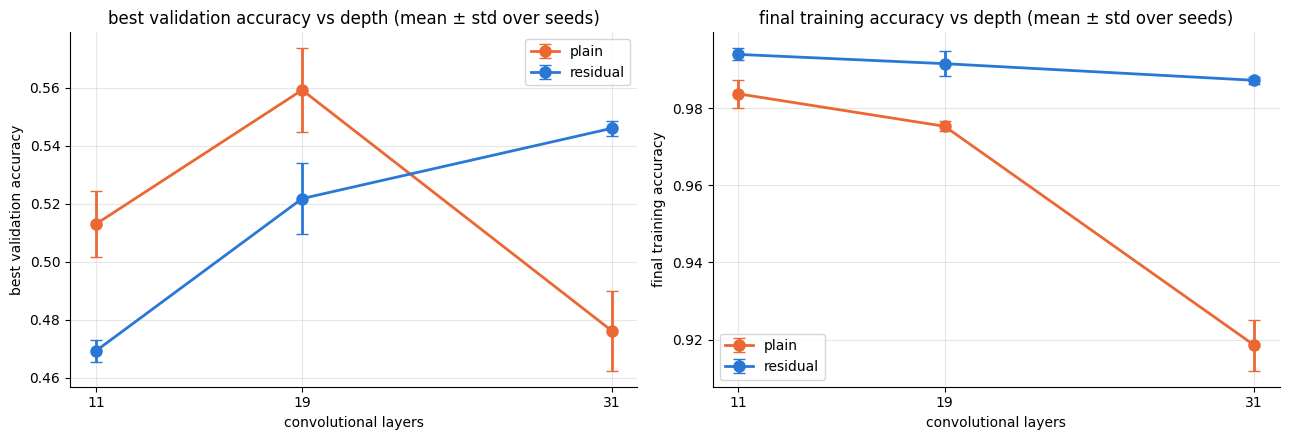

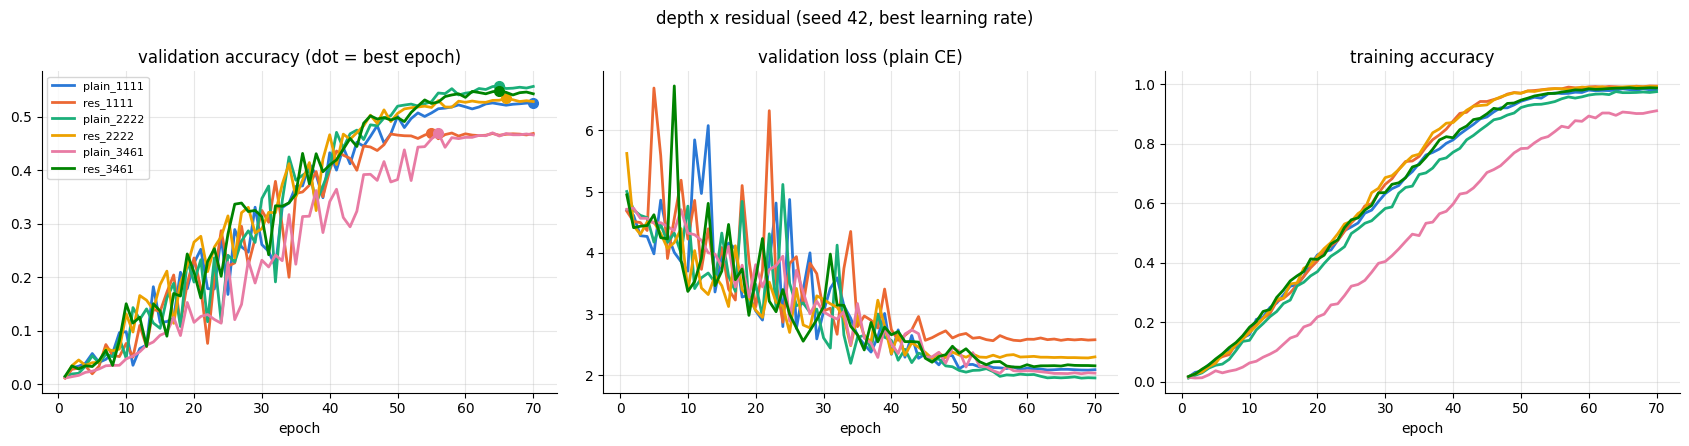

In [28]:
grid_runs = {n: seed_runs(n, "depth_residual") for n, _ in GRID}
grid_runs = {n: r for n, r in grid_runs.items() if r}
if grid_runs:
    display(seed_summary(grid_runs))

    convs = {n: 3 + 2 * sum(dict(GRID)[n]["blocks"]) for n in grid_runs}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for kind, label, c in (("plain", "plain", COLORS[1]), ("res", "residual", COLORS[0])):
        names = [n for n in grid_runs if n.startswith(kind + "_")]
        if not names:
            continue
        for ax, key in zip(axes, ("best_val_acc", "final_train_acc")):
            ax.errorbar([convs[n] for n in names], [seed_mean(grid_runs[n], key) for n in names],
                        yerr=[np.nan_to_num(seed_std(grid_runs[n], key)) for n in names],
                        fmt="o-", color=c, capsize=4, markersize=8, label=label)
    for ax, t in zip(axes, ("best validation accuracy", "final training accuracy")):
        ax.set_xlabel("convolutional layers"); ax.set_ylabel(t); ax.set_xticks(sorted(set(convs.values())))
        ax.set_title(f"{t} vs depth (mean ± std over seeds)"); ax.legend()
    plt.tight_layout(); plt.show()

    plot_curves({n: r[0] for n, r in grid_runs.items()}, "depth x residual (seed 42, best learning rate)")

### Recipe tuning

**Grid search** (seed 42). Accuracy increases with weight decay up to 2e-3 for `plain_2222` and 5e-3 for both
residual networks, then drops sharply at 1e-2, so the optimum lies inside the grid. The residual networks, which fit
their training set more easily, need the stronger regularization. With strong weight decay, lr 0.05 is better than
0.1.

In [30]:
names = finalists(TUNE_N) or []
grid_runs_t = load_group("tune_grid")
for name in names:
    runs = {n: r for n, r in grid_runs_t.items() if n.startswith(name + "_")}
    if runs:
        table = pd.DataFrame({f"wd {wd:g}": {f"lr {lr:g}": runs.get(f"{name}_lr{lr:g}_wd{wd:g}", {}).get("best_val_acc", np.nan)
                                              for lr in TUNE_LRS} for wd in TUNE_WDS})
        print(name)
        display(table.style.format("{:.3f}").highlight_max(axis=None, color="#cde2fb"))

plain_2222


,wd 0.0001,wd 0.0005,wd 0.001,wd 0.002,wd 0.005,wd 0.01
lr 0.1,0.570,0.560,0.562,0.525,0.422,0.240
lr 0.05,0.568,0.597,0.604,0.610,0.551,0.447


res_3461


,wd 0.0001,wd 0.0005,wd 0.001,wd 0.002,wd 0.005,wd 0.01
lr 0.1,0.576,0.583,0.620,0.601,0.569,0.409
lr 0.05,0.559,0.590,0.604,0.618,0.625,0.553


res_2222


,wd 0.0001,wd 0.0005,wd 0.001,wd 0.002,wd 0.005,wd 0.01
lr 0.1,0.524,0.569,0.601,0.605,0.570,0.395
lr 0.05,0.514,0.543,0.563,0.593,0.619,0.569


**Random search** (seed 42), sorted by the mean over the three networks; the plot shows, for each parameter value, the
accuracy of the runs that used it.

The ranking is consistent across networks. The same configuration (`cfg05`: label smoothing 0.2, no dropout, random
erasing 0.25, minimum crop 50%, one-cycle) is the best or second best for all three. The one-cycle schedule appears in
the best configurations, no dropout in the two best, and random erasing at 0.5 in all of the worst ones.

,label_smoothing,dropout,random_erasing,crop_min,schedule,plain_2222,res_3461,res_2222,mean
cfg,,,,,,,,,
cfg05,0.200000,0.000000,0.250000,0.500000,onecycle,0.618,0.644,0.647,0.636
cfg11,0.100000,0.000000,0.000000,0.350000,onecycle,0.615,0.651,0.622,0.629
cfg08,0.050000,0.200000,0.000000,0.500000,cosine,0.593,0.630,0.627,0.617
cfg10,0.000000,0.000000,0.000000,0.350000,onecycle,0.595,0.633,0.616,0.615
cfg00,0.000000,0.200000,0.000000,0.350000,onecycle,0.603,0.629,0.611,0.614
cfg03,0.200000,0.500000,0.000000,0.350000,onecycle,0.598,0.612,0.623,0.611
cfg01,0.050000,0.500000,0.000000,0.500000,cosine,0.586,0.605,0.611,0.600
cfg04,0.050000,0.200000,0.000000,0.350000,cosine,0.559,0.624,0.606,0.596
cfg07,0.200000,0.200000,0.500000,0.250000,onecycle,0.559,0.546,0.566,0.557


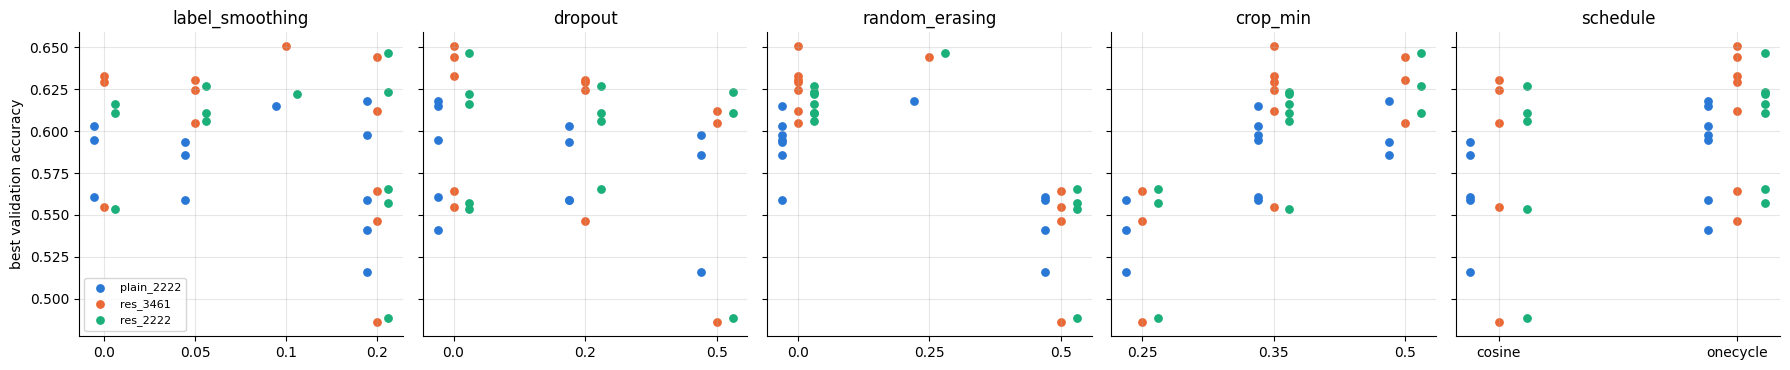

In [31]:
random_runs = load_group("tune_random")
configs = random_configs()
if names and random_runs:
    rows = []
    for i, c in enumerate(configs):
        row = dict(cfg=f"cfg{i:02d}", label_smoothing=c["label_smoothing"], dropout=c["dropout"],
                   random_erasing=c["random_erasing"], crop_min=c["crop_scale"][0],
                   schedule=c.get("schedule", "cosine"))
        for name in names:
            r = random_runs.get(f"{name}_cfg{i:02d}")
            row[name] = r["best_val_acc"] if r else np.nan
        rows.append(row)
    table = pd.DataFrame(rows).set_index("cfg")
    table["mean"] = table[names].mean(axis=1)
    display(table.sort_values("mean", ascending=False).style.format({n: "{:.3f}" for n in names + ["mean"]}))

    params = ["label_smoothing", "dropout", "random_erasing", "crop_min", "schedule"]
    fig, axes = plt.subplots(1, len(params), figsize=(18, 3.8), sharey=True)
    for ax, p in zip(axes, params):
        values = sorted(table[p].unique(), key=str)
        for j, name in enumerate(names):
            for k, v in enumerate(values):
                ys = table.loc[table[p] == v, name].dropna()
                ax.scatter([k + (j - 1) * 0.12] * len(ys), ys, color=COLORS[j], s=28,
                           label=name if (p == params[0] and k == 0) else None)
        ax.set_xticks(range(len(values)), [str(v) for v in values]); ax.set_title(p)
    axes[0].set_ylabel("best validation accuracy"); axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

**Confirmation and final choice**: the two best configurations of each network, mean ± standard deviation over
three seeds; summary of the best one per network:

| network | best configuration | validation | test |
|---|---|---|---|
| `res_3461` | `cfg05`, lr 0.05, wd 5e-3 | 64.2 ± 0.3 | 64.7 ± 0.5 |
| `res_2222` | `cfg05`, lr 0.05, wd 5e-3 | 64.1 ± 0.7 | 64.0 ± 0.3 |
| `plain_2222` | `cfg05`, lr 0.05, wd 2e-3 | 63.0 ± 1.1 | 63.1 ± 0.8 |

The two residual networks are within 0.1 points, far less than one standard deviation, so by our selection rule we
choose the simpler one: **`res_2222`**, a residual network with 19 convolutional layers (the stage layout of
ResNet-18), with label smoothing 0.2, random erasing 0.25, crops of at least 50% of the image, no dropout, weight decay
5e-3 and a one-cycle schedule peaking at lr 0.05.

Tuning confirms the hypothesis of the depth x residual experiment: without regularization the 19-layer residual
network was 3.7 points *worse* than the plain one; with a tuned recipe it is 1.1 points *better*. The ease of fitting
given by the skip connections turns into accuracy once overfitting is controlled. The final model therefore combines
every component justified by the ladder — BatchNorm, global average pooling, augmentation, a fourth stage, depth and
residual connections — with a tuned training recipe.

,lr,seeds,params_M,val_mean,val_std,test_mean,test_std,train_mean
run,,,,,,,,
plain_2222 | default recipe,0.05,3,11.07,0.597,0.004,0.595,0.003,0.908
plain_2222 | cfg05,0.05,3,11.07,0.630,0.011,0.631,0.008,0.892
plain_2222 | cfg11,0.05,3,11.07,0.608,0.006,0.599,0.010,0.928
res_3461 | default recipe,0.05,3,11.91,0.580,0.011,0.579,0.010,0.924
res_3461 | cfg11,0.05,3,11.91,0.638,0.012,0.633,0.011,0.949
res_3461 | cfg05,0.05,3,11.91,0.642,0.003,0.647,0.005,0.905
res_2222 | cfg05,0.05,3,11.25,0.641,0.007,0.640,0.003,0.931
res_2222 | cfg08,0.05,3,11.25,0.627,0.001,0.623,0.010,0.978


res_3461    best config res_3461_cfg05: val 0.642 ± 0.003 | test 0.647 ± 0.005
res_2222    best config res_2222_cfg05: val 0.641 ± 0.007 | test 0.640 ± 0.003
plain_2222  best config plain_2222_cfg05: val 0.630 ± 0.011 | test 0.631 ± 0.008
-> a tie (0.001 <= 0.007): the simpler network, res_2222
final configuration: {'img_size': 224, 'augment': True, 'crop_scale': [0.5, 1.0], 'stem': [32, 32, 64], 'channels': [64, 128, 256, 512], 'blocks': [2, 2, 2, 2], 'batchnorm': True, 'gap': True, 'residual': True, 'dropout': 0.0, 'epochs': 70, 'batch_size': 64, 'lr': 0.05, 'momentum': 0.9, 'weight_decay': 0.005, 'label_smoothing': 0.2, 'random_erasing': 0.25, 'warmup_epochs': 3, 'schedule': 'onecycle'}


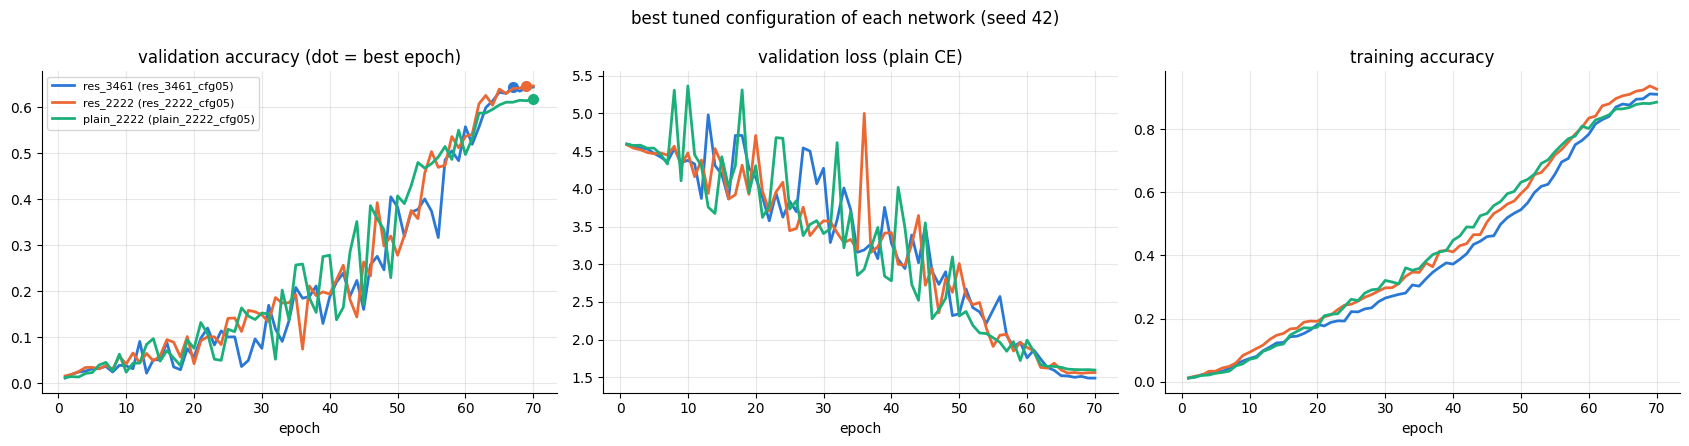

In [32]:
if names:
    groups, best_per_net = {}, {}
    for name in names:
        conf = {n: runs for n, runs in confirmed(name).items() if len(runs) == len(SEEDS)}
        for n, runs in conf.items():
            groups[f"{name} | {n.removeprefix(name + '_')}"] = runs
        if conf:
            best = max(conf, key=lambda n: seed_mean(conf[n]))
            best_per_net[name] = (best, conf[best])
    if groups:
        display(seed_summary(groups))

    if len(best_per_net) == len(names):
        ranked = sorted(best_per_net, key=lambda n: -seed_mean(best_per_net[n][1]))
        for n in ranked:
            cfg_name, runs = best_per_net[n]
            print(f"{n:11s} best config {cfg_name}: val {seed_mean(runs):.3f} ± {seed_std(runs):.3f} | "
                  f"test {seed_mean(runs, 'test_acc'):.3f} ± {seed_std(runs, 'test_acc'):.3f}")
        first, second = ranked[0], ranked[1]
        diff = seed_mean(best_per_net[first][1]) - seed_mean(best_per_net[second][1])
        noise = max(seed_std(best_per_net[first][1]), seed_std(best_per_net[second][1]))
        if diff > noise:
            final = first
            print(f"-> {first}: better by {diff:.3f}, more than one standard deviation ({noise:.3f})")
        else:
            final = min((first, second), key=simplicity)
            print(f"-> a tie ({diff:.3f} <= {noise:.3f}): the simpler network, {final}")
        print("final configuration:", run_overrides(best_per_net[final][1][0]))
        plot_curves({f"{n} ({best_per_net[n][0]})": best_per_net[n][1][0] for n in ranked},
                    "best tuned configuration of each network (seed 42)")